# Study 6: fitted parameters and linking-function components (original Beta-mixture linking)

Study 6 preregistered data, the **original** per-feature Beta-mixture linking function (not the ZOIB one).
Exact 0 and 100 ratings are moved half a slider bin inward, as the loader does. Reads the fits written
by `run_parameter_estimation.py` to `results/study6-fit/`: the full model (fitted length scale) and its
distance-blind null (length scale fixed at `LS_FLAT`). The upper bound on speaker β was widened to
1000 (plausible bound 300), as in the ablations and the earlier study-6 fit. With the default bound of 30
the posterior gets cut off.

For feature j in condition c, a rating r is modeled as

    r ~ pz1[c, j] · Beta(a_kl[j], b_kl[j])  +  (1 − pz1[c, j]) · Beta(a_nkl[j], b_nkl[j])

Each feature has its own shapes, shared across conditions, and there are no point masses.
pz1 is the ratings-free GP coherence for that condition.

1. Posterior over θ = (ls, μ₀, σ, β)
2. The two components of each feature, shown separately (as in section 5b of `zoib-linking-checks.ipynb`)
3. The same components, mixed with each condition's own coherence
4. Shape table

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
from scipy.stats import beta as sbeta

import inference as inf
import studies68 as s68

RESULTS_DIR = 'results/study6-fit'
BETA_UB, BETA_PUB = 1000.0, 300.0   # widened speaker-beta box used for these fits (hard / plausible upper)
geom, responses_cond = s68.load_study6_prereg()
CONDS = list(responses_cond)                      # generic, specific, baseline
features, trait, J = geom['test_feature_names'], geom['test_trait'], geom['J']
R = {c: np.asarray(responses_cond[c]) for c in CONDS}   # exact 0/1 nudged half a bin inward
print({c: R[c].shape[0] for c in CONDS}, "participants per condition")

z = np.load(os.path.join(RESULTS_DIR, 'fitted-link-shapes.npz'), allow_pickle=True)
assert [str(f) for f in z['feature_names']] == list(features)
a_kl, b_kl, a_nkl, b_nkl = np.asarray(z['shapes']).T
m_kl, m_nkl = a_kl / (a_kl + b_kl), a_nkl / (a_nkl + b_nkl)
k_kl, k_nkl = a_kl + b_kl, a_nkl + b_nkl
LS, MU, SIG, BETA_SPK = [float(v) for v in z['theta']]
pz1 = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, LS, MU, SIG, beta_speaker=BETA_SPK).items()}
print(f"posterior median θ: ls={LS:.3f}  mu_0={MU:+.3f}  sigma={SIG:.3f}  speaker beta={BETA_SPK:.3f}")

COND_COLOR = {'generic': '#2a78d6', 'specific': '#eb6834', 'baseline': '#1baf7a'}
CLS_COLOR = {'kl': '#2a78d6', 'nkl': '#eb6834'}
MIX_COLOR = '#eda100'
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
})
def grid_y(ax):
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)

load_study6_prereg: 446 of 471 rows kept after exclusions
{'generic': 148, 'specific': 146, 'baseline': 152} participants per condition


posterior median θ: ls=1.695  mu_0=+0.168  sigma=2.003  speaker beta=28.948


## 1. Posterior over θ

Median and 95% interval of the VBMC posterior for the full model and the distance-blind null. The dashed
line in the β panel is the widened plausible upper bound (hard bound 1000). Mass piling up against a bound means the
box, not the data, is setting β.

full             ELBO=1975.6  evals=280  probable  11 min
null (ls fixed)  ELBO=1970.6  evals=365  probable  10 min


fit             full                 null (ls fixed)                
                2.5%   97.5%  median            2.5%   97.5%  median
parameter                                                           
length scale   0.767   3.259   1.695          10.000  10.000  10.000
μ₀            -0.017   0.237   0.168          -0.248   0.173   0.055
σ              1.273   3.231   2.003           1.750   6.496   3.565
speaker β     13.016  71.910  28.948          10.027  64.672  21.697

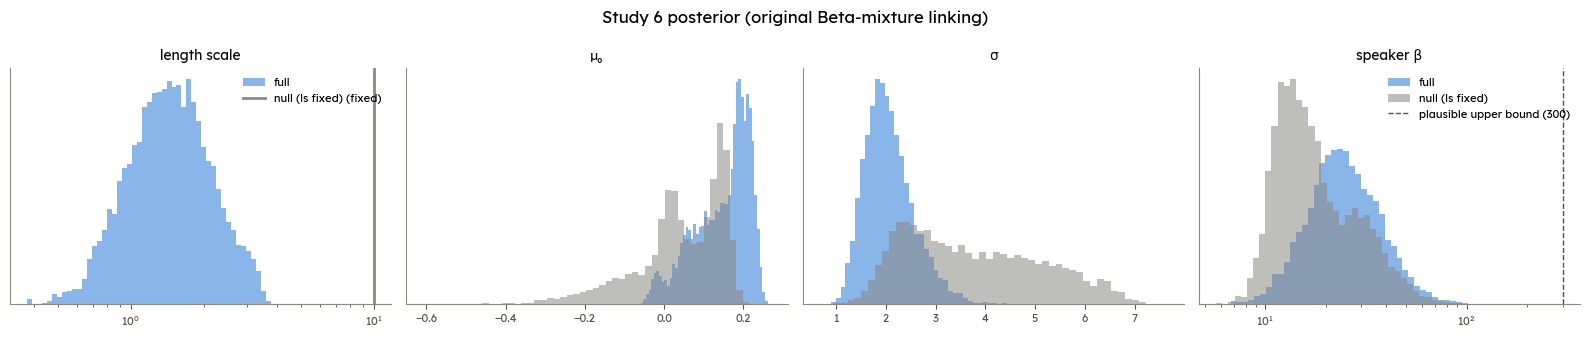

In [2]:
KEYS = [('length scale', 'ls_samples'), ('μ₀', 'mu0_samples'), ('σ', 'sigma_samples'), ('speaker β', 'beta_samples')]
FITS = {'full': 'fitted-feature-shapes.npz', 'null (ls fixed)': 'fitted-feature-shapes-null.npz'}
post, rows = {}, []
for name, fn in FITS.items():
    zz = np.load(os.path.join(RESULTS_DIR, fn), allow_pickle=True)
    meta = json.loads(str(zz['meta']))
    post[name] = {k: np.asarray(zz[k]) for _, k in KEYS}
    for lab, k in KEYS:
        s = post[name][k]
        rows.append({'fit': name, 'parameter': lab, 'median': np.median(s),
                     '2.5%': np.percentile(s, 2.5), '97.5%': np.percentile(s, 97.5)})
    print(f"{name:<16} ELBO={meta['elbo']:.1f}  evals={meta['func_count']}  "
          f"{meta['convergence_status']}  {meta['runtime_s'] / 60:.0f} min")
display(pd.DataFrame(rows).pivot_table(index='parameter', columns='fit', values=['median', '2.5%', '97.5%'],
                                       sort=False).swaplevel(axis=1).sort_index(axis=1, level=0).round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (lab, k) in zip(axes, KEYS):
    for name, col in zip(FITS, ['#2a78d6', MUTED]):
        s = post[name][k]
        if np.ptp(s) < 1e-9:                      # the null's pinned length scale
            ax.axvline(s[0], color=col, lw=2, label=f'{name} (fixed)')
            continue
        bins = np.geomspace(s.min(), s.max(), 50) if k in ('beta_samples', 'ls_samples') else 50
        ax.hist(s, bins=bins, density=True, color=col, alpha=0.55, label=name)
    if k in ('beta_samples', 'ls_samples'):
        ax.set_xscale('log')
    if k == 'beta_samples':
        ax.axvline(BETA_PUB, color=TEXT_2, lw=1, ls='--', label=f'plausible upper bound ({BETA_PUB:.0f})')
        ax.legend(loc='upper right')
    ax.set_title(lab, color=TEXT_1); ax.set_yticks([])
axes[0].legend(loc='upper right')
fig.suptitle('Study 6 posterior (original Beta-mixture linking)', fontsize=12)
fig.tight_layout(); plt.show()

## 2. The two components of each feature, separately

As in section 5b of `zoib-linking-checks.ipynb`, but for the original linking function. That function has
**no point masses**, so each component is just a Beta density and integrates to 1. There's no
(1 − P(0) − P(100)) scaling and no P(0)/P(100) text.
- **blue / orange curve**: kind-linked (kl) / not-kind-linked (nkl) component, Beta(a, b);
- **dashed line**: the component's mean m;
- **yellow**: the feature's final linking function, the two components mixed using coherence averaged
  over participants across the three conditions (the mixture is linear in coherence, so this equals the
  participant-weighted average of the three conditions' mixtures);
- **grey histogram**: the feature's pooled ratings (density), including the nudged 0s and 100s.

Components with a < 1 or b < 1 shoot up at the edge (U- or J-shaped). The y-axis is capped so the bulk of
the plot stays readable, and an arrow marks a component that runs off the top.

average coherence per feature: 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49, 0.49


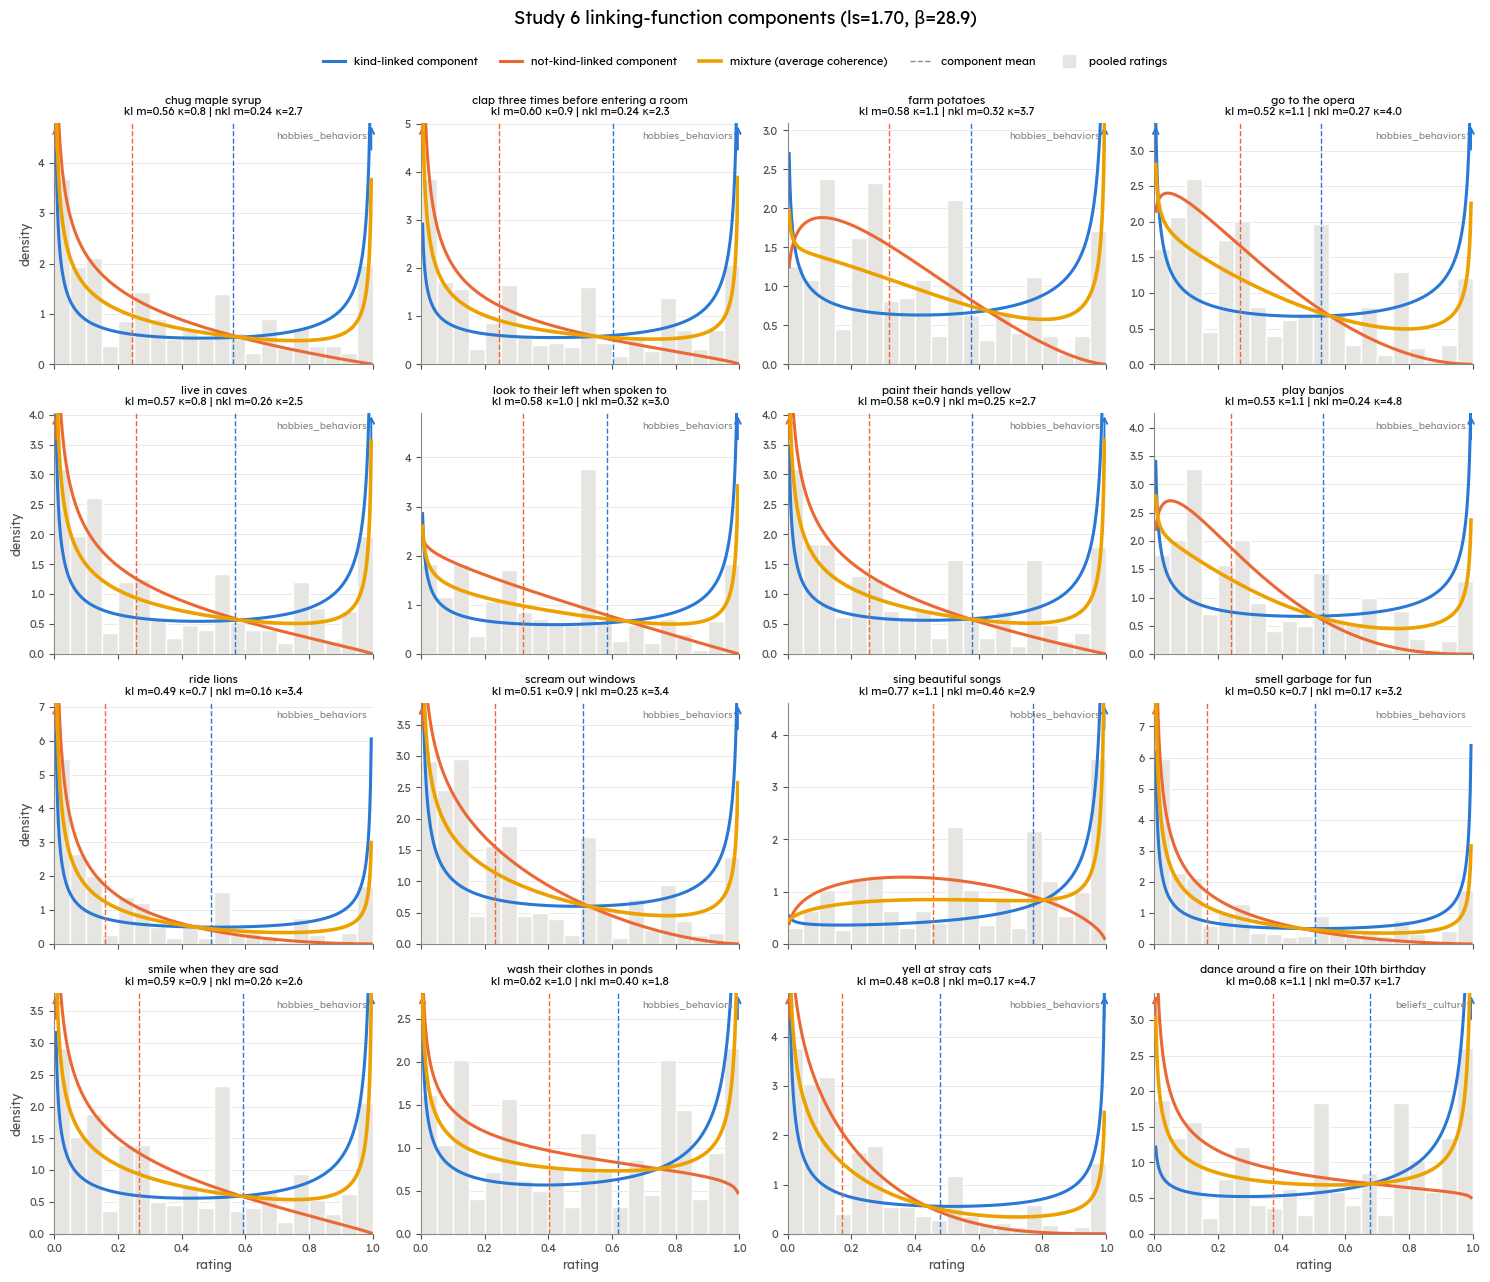

In [3]:
XG = np.linspace(0.005, 0.995, 400)
HBINS = np.linspace(0, 1, 21)
ORDER = [j for t in dict.fromkeys(trait) for j in range(J) if trait[j] == t]
n_c = np.array([R[c].shape[0] for c in CONDS], float)
pz1_bar = np.sum([n * pz1[c] for n, c in zip(n_c, CONDS)], axis=0) / n_c.sum()
Rall = np.concatenate([R[c] for c in CONDS])

def comp(j, c):
    a, b = (a_kl[j], b_kl[j]) if c == 'kl' else (a_nkl[j], b_nkl[j])
    return sbeta.pdf(XG, a, b)

def panel(ax, j, mixes, cc=CLS_COLOR, cls_ls='-', cls_lw=2.2):
    h = ax.hist(Rall[:, j], bins=HBINS, density=True, color=GRID, edgecolor='white')[0]
    body = [h.max()]
    for c in ('kl', 'nkl'):
        y = comp(j, c)
        ax.plot(XG, y, color=cc[c], lw=cls_lw, ls=cls_ls)
        ax.axvline(m_kl[j] if c == 'kl' else m_nkl[j], color=cc[c], lw=1, ls=':' if cls_ls == '--' else '--')
        body.append(y[40:-40].max())              # bulk height, ignoring the edge spikes
    for w, col, lw in mixes:
        y = w * comp(j, 'kl') + (1 - w) * comp(j, 'nkl')
        ax.plot(XG, y, color=col, lw=lw, zorder=4)
        body.append(y[40:-40].max())
    top = 1.3 * max(body)
    for c in ('kl', 'nkl'):
        y = comp(j, c)
        for x_e, y_e in [(XG[0], y[0]), (XG[-1], y[-1])]:
            if y_e > top:
                ax.annotate('', (x_e, top), xytext=(x_e, 0.88 * top),
                            arrowprops=dict(arrowstyle='->', color=cc[c], lw=1.4))
    ax.set_ylim(0, top); ax.set_xlim(0, 1); grid_y(ax)
    ax.set_title(f"{features[j]}\nkl m={m_kl[j]:.2f} κ={k_kl[j]:.1f} | nkl m={m_nkl[j]:.2f} κ={k_nkl[j]:.1f}",
                 fontsize=8, color=TEXT_1)

def grid_fig(mix_fn, extra_legend, title, cc=CLS_COLOR, cls_ls='-', cls_lw=2.2):
    nrow = int(np.ceil(J / 4))
    fig, axes = plt.subplots(nrow, 4, figsize=(15, 3.1 * nrow), sharex=True)
    for ax, j in zip(axes.ravel(), ORDER):
        panel(ax, j, mix_fn(j), cc, cls_ls, cls_lw)
        ax.text(0.98, 0.97, trait[j], transform=ax.transAxes, ha='right', va='top', fontsize=7, color=MUTED)
    for ax in axes.ravel()[J:]:
        ax.axis('off')
    for ax in axes[-1]:
        ax.set_xlabel('rating')
    for ax in axes[:, 0]:
        ax.set_ylabel('density')
    leg = [Line2D([], [], color=cc['kl'], lw=cls_lw, ls=cls_ls, label='kind-linked component'),
           Line2D([], [], color=cc['nkl'], lw=cls_lw, ls=cls_ls, label='not-kind-linked component')]
    leg += extra_legend
    leg += [Line2D([], [], color=MUTED, lw=1, ls=':' if cls_ls == '--' else '--', label='component mean'),
            Line2D([], [], marker='s', ls='', color=GRID, ms=9, label='pooled ratings')]
    fig.legend(handles=leg, loc='upper center', ncol=len(leg), bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, y=1.03, fontsize=13)
    fig.tight_layout(); plt.show()

print("average coherence per feature: " + ", ".join(f"{v:.2f}" for v in pz1_bar[ORDER]))
grid_fig(lambda j: [(pz1_bar[j], MIX_COLOR, 2.6)],
         [Line2D([], [], color=MIX_COLOR, lw=2.6, label='mixture (average coherence)')],
         f"Study 6 linking-function components (ls={LS:.2f}, β={BETA_SPK:.1f})")

## 3. Mixed with each condition's own coherence

In study 6, coherence changes a lot between conditions (generic vs specific), so the single
average-coherence mixture above is a mixture that no condition actually uses. Here the components are drawn
the same way, but with one mixture per condition, each using that condition's own pz1. The components
are drawn as grey dashed lines here (dark = kl, light = nkl), so the condition colors stay distinct.

          generic  specific  baseline
pz1 min     0.876     0.050     0.542
pz1 mean    0.881     0.052     0.542
pz1 max     0.883     0.056     0.542


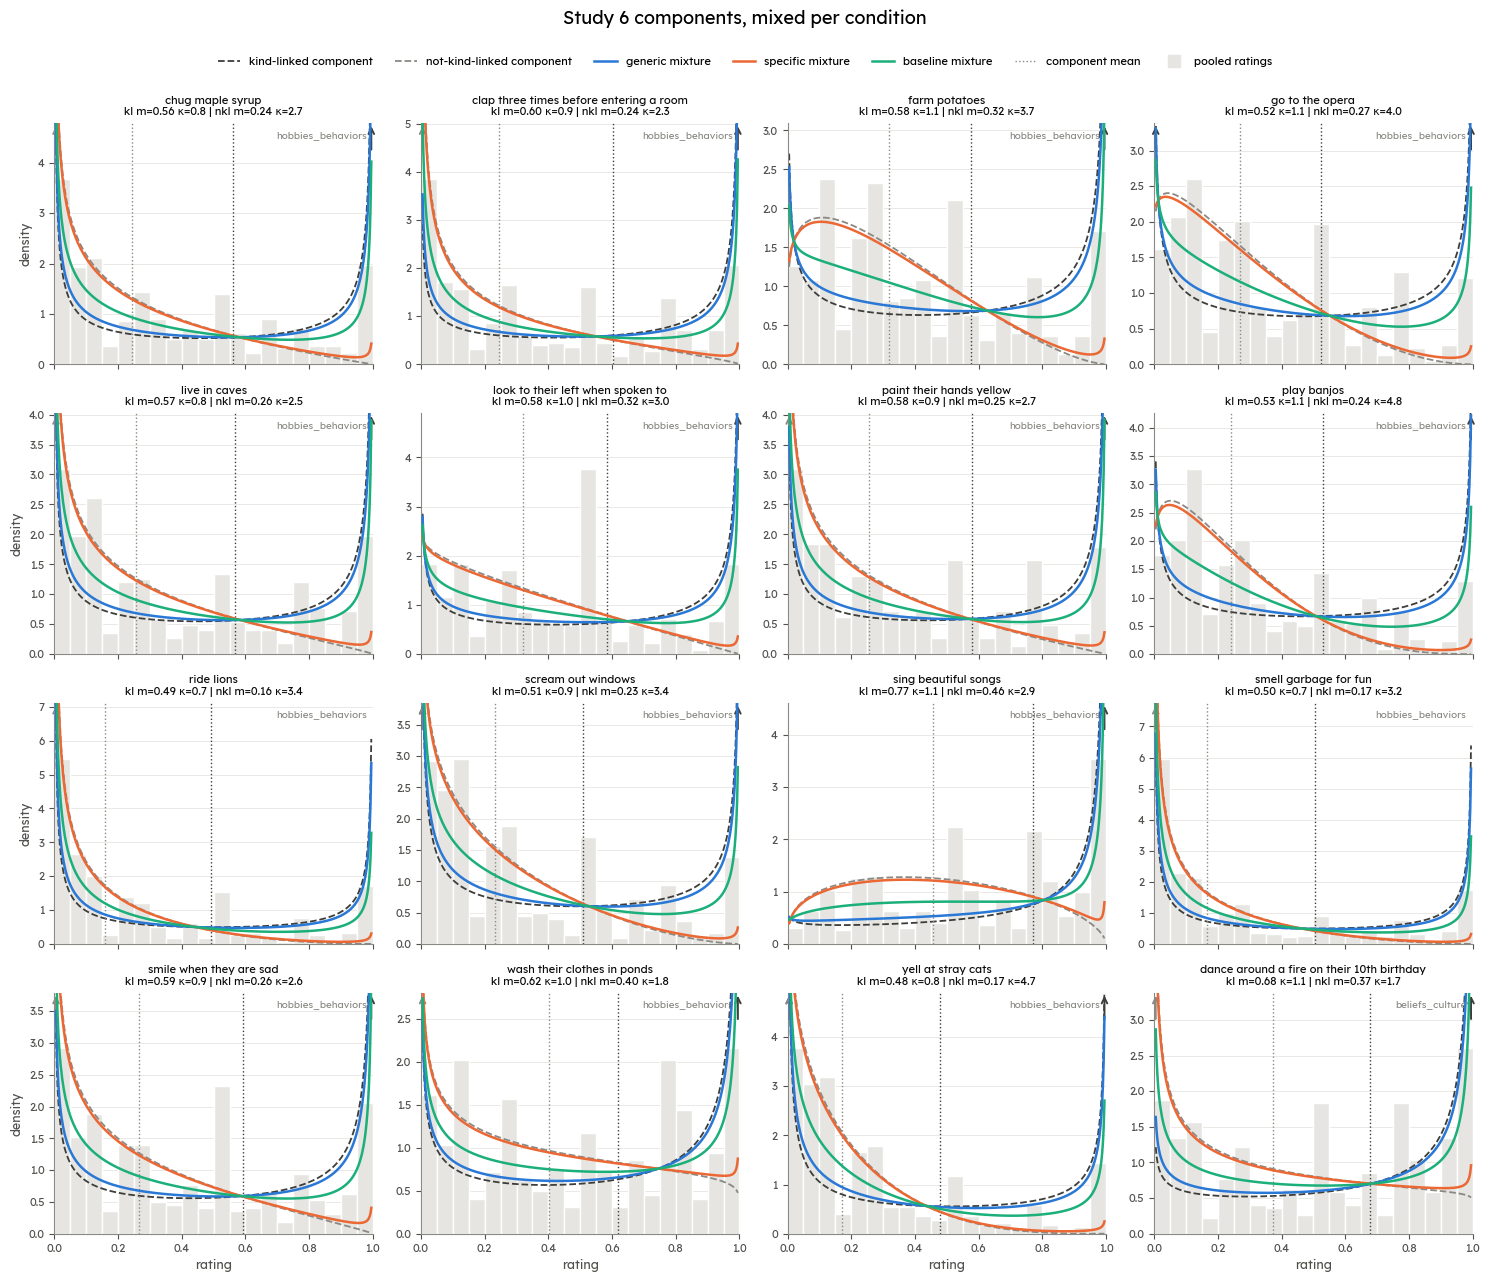

In [4]:
print(pd.DataFrame({c: [pz1[c].min(), pz1[c].mean(), pz1[c].max()] for c in CONDS},
                   index=['pz1 min', 'pz1 mean', 'pz1 max']).round(3))
grid_fig(lambda j: [(pz1[c][j], COND_COLOR[c], 1.8) for c in CONDS],
         [Line2D([], [], color=COND_COLOR[c], lw=1.8, label=f'{c} mixture') for c in CONDS],
         "Study 6 components, mixed per condition",
         cc={'kl': '#3d3d3a', 'nkl': MUTED}, cls_ls='--', cls_lw=1.3)

## 4. Shape table

In [5]:
pd.DataFrame({'feature': features, 'trait': trait,
              'a_kl': a_kl, 'b_kl': b_kl, 'm_kl': m_kl, 'κ_kl': k_kl,
              'a_nkl': a_nkl, 'b_nkl': b_nkl, 'm_nkl': m_nkl, 'κ_nkl': k_nkl,
              **{f'pz1 {c}': pz1[c] for c in CONDS}}).iloc[ORDER].round(3).reset_index(drop=True)

,feature,trait,a_kl,b_kl,m_kl,κ_kl,a_nkl,b_nkl,m_nkl,κ_nkl,pz1 generic,pz1 specific,pz1 baseline
0,chug maple syrup,hobbies_behaviors,0.434,0.339,0.562,0.773,0.648,2.022,0.243,2.670,0.877,0.055,0.542
1,clap three times before entering a room,hobbies_behaviors,0.548,0.361,0.603,0.909,0.570,1.767,0.244,2.337,0.879,0.053,0.542
2,farm potatoes,hobbies_behaviors,0.605,0.447,0.575,1.051,1.188,2.533,0.319,3.721,0.880,0.053,0.542
3,go to the opera,hobbies_behaviors,0.572,0.520,0.524,1.092,1.088,2.957,0.269,4.045,0.877,0.055,0.542
4,live in caves,hobbies_behaviors,0.475,0.363,0.567,0.838,0.638,1.859,0.256,2.497,0.883,0.050,0.542
5,look to their left when spoken to,hobbies_behaviors,0.575,0.408,0.585,0.984,0.957,2.017,0.322,2.975,0.882,0.051,0.542
6,paint their hands yellow,hobbies_behaviors,0.514,0.376,0.578,0.889,0.681,1.993,0.255,2.674,0.883,0.050,0.542
7,play banjos,hobbies_behaviors,0.573,0.508,0.530,1.081,1.143,3.623,0.240,4.766,0.879,0.053,0.542
8,ride lions,hobbies_behaviors,0.345,0.358,0.491,0.703,0.535,2.866,0.157,3.401,0.882,0.051,0.542
9,scream out windows,hobbies_behaviors,0.469,0.452,0.510,0.921,0.779,2.582,0.232,3.362,0.883,0.050,0.542
